<small>📌 <b>먼저 내 노트로 저장하기</b></small><br><small>이 노트는 내 구글 드라이브의 『Colab Notebooks』 폴더(자동 사본으로 만들었으면 『배화 Colab 실습』 폴더)에 저장돼요.</small><br><small>사이트의 「▶ 내 Colab 노트 만들기」로 열었으면 사본·공유가 이미 돼 있어요 — 아래 ①~③ 은 건너뛰어도 돼요.</small><br><br><small>① 맨 위 <b>파일 → Drive에 사본 저장</b> (안 하면 쓴 게 사라져요)</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_copy.jpg" width="300"><br><br><small>② 사본이 열리면 오른쪽 위 <b>공유</b> 단추를 눌러요.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_share.jpg" width="300"><br><br><small>③ 일반 액세스에서 <b>「링크가 있는 모든 사용자」</b>를 고른 다음 <b>링크 복사</b> → 수행평가 화면 「📓 내 Colab 실습 노트」 칸에 붙여넣고 보관해요.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_anyone.jpg" width="300">

# 📈 역사 속 전쟁 사망자 규모(전쟁 크기 멱법칙) — 데이터 분석 빈칸 실습

서울대 역사학부에서 다루는 주제예요. 역사 속 전쟁 사망자 규모(전쟁 크기 멱법칙)을(를) 논문 공식(P(규모 > x) ∝ x^(−α))으로 흉내 낸 연습용 데이터예요. 전쟁 규모 · 지수 α을(를) 바꿔 가며 더 큰 전쟁 확률이(가) 어떻게 달라지는지 찾아봐요.

**핵심 속성(변수)**
- **전쟁 규모**(천 명) — 전쟁 규모(천 명) — 1~10000 사이에서 바뀌어요
- **지수 α**(값) — 지수 α(값) — 1.3~1.7 사이에서 바뀌어요
- **결과** — 더 큰 전쟁 확률(%) 값이에요

**기타 속성** — 결과와 관련이 있을까? 상관을 보고 넣을지 뺄지 **내가 골라요**.
- 측정한 요일 — 자료를 기록한 요일을 숫자로 나타낸 값이에요. 분석과는 관련 없는 미끼 항목이에요.
- 기록 담당자 번호 — 자료를 기록한 담당자에게 붙인 번호예요. 분석과는 관련 없는 미끼 항목이에요.
- 주변 온도(℃) — 그 순간 주변 공기의 온도예요. 분석과는 관련 없는 미끼 항목이에요.
- 관찰 메모 길이(자) — 그날 적은 관찰 메모의 글자 수예요. 분석과는 관련 없는 미끼 항목이에요.
- 전쟁 규모 (다시 잰 값) — 전쟁 규모를 다시 한 번 측정한 값이에요(같은 것을 두 번 잼). 분석에는 안 써요.

> ⚠️ 연습용 합성 데이터(실제 측정 아님)

### 오늘 할 일 (약 30분) — 수업에서 배운 순서 그대로
1. 불러오기 → 2. 결측치 → 3. 이상치(IQR) → 4. 요약 → 5. 그래프 → 6. pairplot·상관계수·heatmap 으로 속성 고르기 → 7. train_test_split → 7-1. 정규화(0~1) → 8. 회귀 모델 → 9. 심화(분류·KNN·confusion matrix·ROC·AUC·내 생각 정리)

`______` 빈칸에 알맞은 **함수 이름이나 숫자**를 넣고 ▶ 실행해요. 막히면 **오픈북** — 클래스룸에 올린 그간의 실습 파일(Pandas 문법·결측치·이상치·예측·분류)을 펴 보고 같은 코드를 찾아 써요. 단계마다 📖 에 어느 파일 몇 번 숙제인지 적어 두었어요.

In [ ]:
# 0. 준비 — 그대로 실행해요 (한글 그래프 글꼴)
!pip -q install koreanize-matplotlib
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib

## 1. 데이터 불러오기
CSV 파일을 표(DataFrame)로 읽어요. 함수 이름은 **읽다(read) + csv**.

📖 **오픈북** — 「#16 펭귄-분류」 숙제01 `pd.read_csv(url)` · 「Pandas 문법-(A~E)」 `df.head()`

In [ ]:
URL = "https://baehwa-ai-2026.web.app/dataproject/csv/c2286_n.csv"
df = pd.______(URL)      # 힌트: CSV 를 읽는 함수
print(df.shape)          # (행 수, 열 수)
df.______()              # 힌트: 위에서 5줄만 미리보기(모양만 보기, df는 안 바뀌어요)

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)


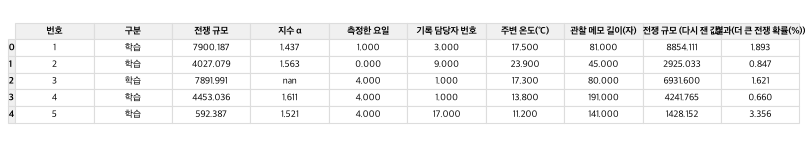

## 2. 결측치(빈칸) 처리
빈칸이 몇 개인지 세고, 빈칸이 있는 줄을 지워요. (평균으로 채우는 `fillna(df[열].mean())` 도 배웠죠 — 해 보고 싶으면 바꿔 봐요.)

📖 **오픈북** — 「#16 펭귄-분류」 숙제05 `df.isnull().sum()` · 숙제06 `df.dropna(axis=0)` · 「#12 결측치(seoultemp)」

In [ ]:
print(df.______().sum())   # 힌트: 빈칸인지 True/False — 열마다 개수
df = df.______()            # 힌트: 위 미리보기와 다른 함수 — 빈칸(NaN) 있는 '줄'을 통째로 지워서 df를 바꿔요
print('빈칸 지운 뒤', df.shape)      # 기타 속성에 빈칸이 많으면 많이 줄 수 있어요(예: 300줄 → 141줄도 정상)

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)

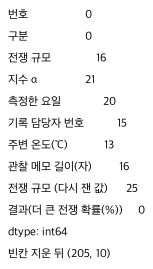

## 3. 이상치(IQR) 처리
값을 작은 것부터 줄 세웠을 때 4분의 1 지점이 Q1, 4분의 3 지점이 Q3 예요. 둘 사이 거리를 IQR 이라고 해요(가운데 절반이 퍼진 폭). **Q1 − 1.5×IQR 보다 작거나 Q3 + 1.5×IQR 보다 크면 이상치**로 보고 지워요.

단, 1~4 등급이나 「거의 0인 횟수」처럼 **값 종류가 몇 개뿐인 열은 건너뛰어요** — 그런 열의 드문 값은 이상치가 아니라 정상이에요.

📖 **오픈북** — 「#14 Iris 데이터 전처리(이상치)」 숙제14 `quantile(0.25)` · 숙제15 `Q3 + 1.5 * IQR`

In [ ]:
for col in ["전쟁 규모", "지수 α"]:
    q1 = df[col].______(0.25)        # 힌트: 분위수
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    if iqr == 0 or df[col].nunique() <= 5: continue      # 값 종류가 적은 열은 건너뛰기
    하한 = q1 - 1.5 * iqr
    상한 = q3 + ______ * iqr          # 힌트: 숫자예요(함수 아님) — IQR 의 몇 배인지
    df = df[(df[col] >= 하한) & (df[col] <= 상한)]
print('이상치 지운 뒤', df.shape)

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)



## 4. 요약 통계
평균·최솟값·최댓값을 한 번에 봐요. 이상치를 지운 뒤 값이 그럴듯해졌나요?

📖 **오픈북** — 「#14 Iris 데이터 전처리(이상치)」 숙제03 `df.describe()`

In [ ]:
df.______()               # 힌트: 위 두 칸과 또 다른 함수 — 평균·최솟값·최댓값 등 숫자 열 요약표

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)

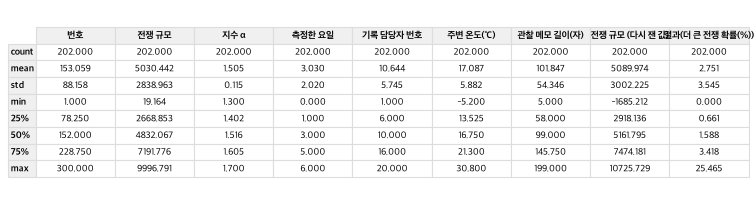

## 5. 관계 그래프
`전쟁 규모` 이(가) 바뀔 때 결과는 어떻게 바뀌나요? 점 그래프(산점도)로 봐요.

📖 **오픈북** — 「목둘레 허리둘레-예측」 숙제09 `plt.scatter(X_test, y_test)`

In [ ]:
plt.______(df["전쟁 규모"], df["결과(더 큰 전쟁 확률(%))"])   # 힌트: 점 그래프(산점도)
plt.xlabel("전쟁 규모"); plt.ylabel("결과(더 큰 전쟁 확률(%))")
plt.show()

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)

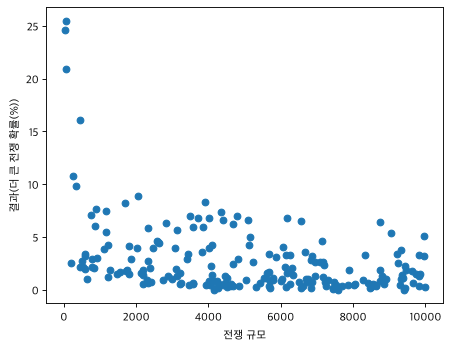

## 6. 상관으로 속성 고르기
결과와의 상관계수예요. 1이나 −1에 가까울수록 관련이 크고, 0 근처면 거의 관련 없어요. **기타 속성은 넣을까요, 뺄까요?**

⚠ 상관이 크다고 「원인」이라는 뜻은 아니에요. 그리고 상관계수는 **직선 관계**만 재요 — 곡선 관계는 0 근처로 나올 수 있어요.

**판단 기준(참고):** 상관계수 절댓값이 대략 0.3보다 작으면 빼고, 0.3 이상이면 넣는 걸 추천해요. 애매하면 넣고 빼고 둘 다 해 보고 8번 점수가 더 높은 쪽으로 정해도 좋아요.

📖 **오픈북** — 「#14 Iris 데이터 전처리(이상치)」 숙제19 `df.corr(numeric_only=True)`

### 6-1. pairplot — 속성끼리 한꺼번에 점 그래프
모든 짝의 점 그래프를 한 번에 그려요. 결과(맨 아래 줄)와 점들이 비스듬한 선을 이루는 속성이 관계가 큰 속성이에요. 📖 **오픈북** — 「#16 펭귄-분류」 `sns.pairplot(df)`

In [ ]:
import seaborn as sns
cols = ["전쟁 규모", "지수 α", "결과(더 큰 전쟁 확률(%))"]
sns.______(df[cols].sample(min(len(df), 300), random_state=0), corner=True, plot_kws={'s': 12})   # 힌트: 짝마다 점 그래프 (p…plot)
plt.show()

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)

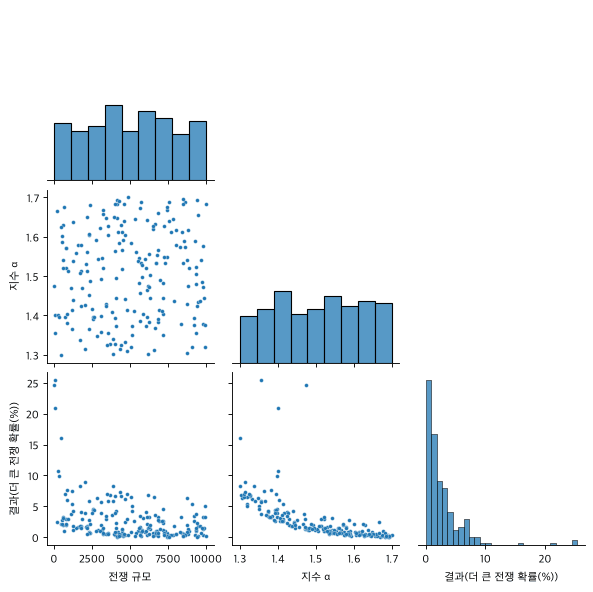

### 6-2. 결과와의 상관계수

In [ ]:
df.______(numeric_only=True)["결과(더 큰 전쟁 확률(%))"].sort_values()   # 힌트: 상관계수

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)

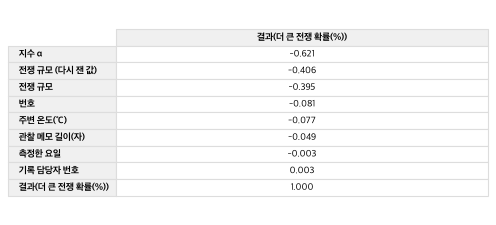

### 6-3. heatmap — 상관계수 표를 색으로
빨갈수록 같이 커지고, 파랄수록 반대로 움직여요. 칸 안 숫자가 상관계수예요. 📖 **오픈북** — 「#14 Iris 데이터 전처리」 `sns.heatmap(df.corr(), annot=True)`

In [ ]:
plt.figure(figsize=(8, 6))
sns.______(df.drop(columns=['번호'], errors='ignore').corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)   # 힌트: 색 표 (h…map)
plt.show()

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)

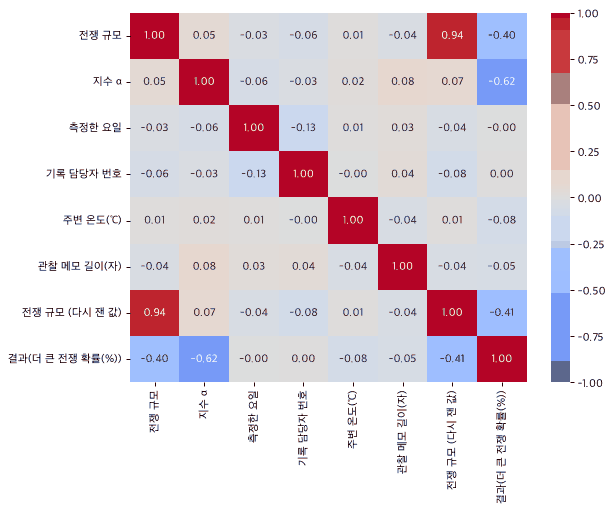

## 7. 학습용 / 시험용 나누기 — train_test_split
수업에서 배운 그대로 30% 를 시험용으로 떼어 놓아요. X 에는 6번에서 고른 속성을 넣어요.

📖 **오픈북** — 「예측-전복나이」 숙제03 · 「#16 펭귄-분류」 숙제07 `train_test_split(X, y, test_size=0.3, random_state=42)`

In [ ]:
from sklearn.model_selection import train_test_split
X = df[["전쟁 규모", "지수 α"]]   # ← 6번을 보고 속성을 넣거나 빼 봐요
y = df["결과(더 큰 전쟁 확률(%))"]
X_train, X_test, y_train, y_test = ______(X, y, test_size=0.3, random_state=42)   # 힌트: 나누는 함수
print(len(X_train), len(X_test))

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)



## 7-1. 정규화 — 숫자 크기를 0~1 로 맞추기
속성마다 숫자 크기가 달라요(어떤 속성은 10~20, 어떤 속성은 수천~수백만). **가장 작은 값은 0, 가장 큰 값은 1** 이 되게 바꿔요.

기준(최솟값·최댓값)은 **학습용에서만** 구해요 — 시험지를 미리 보면 안 되니까요. 시험용도 같은 기준으로 바꿔요. 시험용 값은 학습용 범위를 벗어날 수 있어서 **0보다 작거나 1보다 커질 수 있어요 — 정상이에요.**

선형 회귀는 정규화해도 점수가 거의 같지만, 딥러닝(신경망)은 정규화를 안 하면 잘 못 배워요. 습관처럼 해 둬요.

📖 **오픈북** — 「MNIST 딥러닝」 숙제03 정규화 `X / 255` · 「#20 과일 채소 딥러닝」 min·max 로 0~1

In [ ]:
mn, mx = X_train.min(), X_train.______()      # 힌트: 가장 큰 값 (가장 작은 값은 min)
rng = (mx - mn).replace(0, 1)                 # 값이 한 가지뿐인 열은 0 으로 나누지 않게
X_train = (X_train - mn) / rng
X_test = (X_test - mn) / rng                  # 시험용도 학습용 기준으로 — ⚠️ 이 셀을 두 번 실행하면 이미 줄인 값을 또 줄여요(다시 하려면 1번부터)
X_train.describe().loc[['min', 'max']]        # 학습용은 0 ~ 1 이 됐나요?

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)

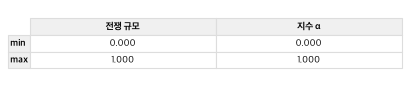

## 8. 예측 모델 만들기 (선형 회귀)
학습용으로 맞추고(fit), 시험용으로 점수(score)를 봐요. 1 에 가까울수록 잘 맞아요.

점수가 0 근처거나 **0보다 작으면** 「그냥 평균으로 찍는 것보다도 못하다」는 뜻이에요 — 고른 속성이 결과를 잘 설명하지 못하거나, 관계가 직선이 아닐 수 있어요. 틀린 게 아니라 **발견**이에요. 보고서 「1-5. 한계」에 적어요.

📖 **오픈북** — 「예측-전복나이」 숙제04 `model.fit(X_train, y_train)` · `model.score(X_test, y_test)`

In [ ]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.______(X_train, y_train)                    # 힌트: 학습시키기
print('시험 점수', model.______(X_test, y_test))   # 힌트: 점수 매기기

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)



## 9. 심화 — 분류형 데이터 둘러보기
같은 모형의 분류형 데이터예요. 결과 `결과(더 큰 전쟁 확률 중간보다 높음)` 별로 속성 평균이 어떻게 다른지 묶어서 봐요.

📖 **오픈북** — 「#14 Iris 데이터 전처리(이상치)」 숙제04 `df.groupby('종류')`

In [ ]:
dc = pd.read_csv("https://baehwa-ai-2026.web.app/dataproject/csv/c2286_c.csv").dropna()
# 이상치가 섞이면 평균이 튀어요 — 3번에서 배운 IQR 거르기를 여기서도 해요
for col in ["전쟁 규모", "지수 α"]:
    q1, q3 = dc[col].quantile(0.25), dc[col].quantile(0.75)
    if q3 == q1 or dc[col].nunique() <= 5: continue      # 값 종류가 적은 열은 건너뛰기
    dc = dc[(dc[col] >= q1 - 1.5 * (q3 - q1)) & (dc[col] <= q3 + 1.5 * (q3 - q1))]
dc.______("결과(더 큰 전쟁 확률 중간보다 높음)").mean(numeric_only=True)   # 힌트: 묶어서(group) 보기

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)

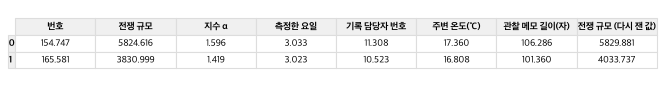

## 9-1. 분류 모델 만들고 평가하기 — confusion matrix
가장 가까운 이웃 몇 개의 답을 보고 정하는 **KNN**(K-최근접이웃)으로 분류해 봐요.

**혼동행렬(confusion matrix)** 은 예측이 실제와 맞았는지·어떻게 틀렸는지 보여주는 표예요. 대각선 칸이 맞춘 개수예요.

📖 **오픈북** — 「#16 펭귄-분류」 KNN 숙제 `KNeighborsClassifier(n_neighbors=...)` · `model.fit` · `model.predict` · `accuracy_score` · `confusion_matrix`

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
Xc, yc_ = dc[["전쟁 규모", "지수 α"]], dc["결과(더 큰 전쟁 확률 중간보다 높음)"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc_, test_size=0.3, random_state=42)
clf = ______(n_neighbors=5)      # 힌트: KNN 분류기
clf.fit(Xc_train, yc_train)
pred = clf.______(Xc_test)       # 힌트: 예측하기
print('정확도', ______(yc_test, pred))      # 힌트: 정확도 재는 함수
cm = ______(yc_test, pred)       # 힌트: 혼동행렬 만들기
ConfusionMatrixDisplay(cm).plot()
plt.show()

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)


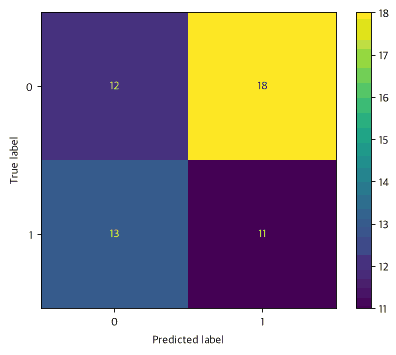

### 9-1-1. ROC 곡선 · AUC
**ROC 곡선**은 「찍는 기준(문턱값)」을 이리저리 바꿔 가며 진짜 양성 비율과 거짓 양성 비율을 그린 선이에요.
곡선이 왼쪽 위 모서리에 붙을수록 잘 가려내는 거예요. **AUC**(곡선 아래 넓이)는 1에 가까울수록 좋고, **0.5면 동전 던져 찍는 것과 같아요.**

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
proba = clf.predict_proba(Xc_test)[:, 1]      # 「예(1)」일 확률
fpr, tpr, _ = ______(yc_test, proba)      # 힌트: ROC 곡선 좌표
auc = ______(yc_test, proba)                 # 힌트: 곡선 아래 넓이
plt.plot(fpr, tpr, label=f'KNN (AUC={auc:.2f})'); plt.plot([0, 1], [0, 1], '--', color='gray', label='찍기 (AUC=0.50)')
plt.xlabel('거짓 양성 비율(FPR)'); plt.ylabel('진짜 양성 비율(TPR)'); plt.legend(); plt.show()
print('AUC', round(auc, 3))

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)


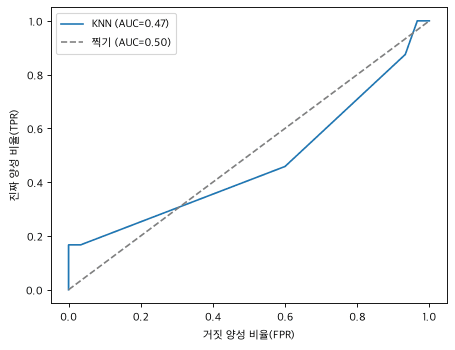

### 9-2. 내 생각 정리
아래를 보고서 「1-4. 그래프 설명」·「1-5. 한계」 칸에 옮겨 써요.
- 그래프에서 읽은 숫자 하나와 그 뜻
- 가장 관련이 큰 속성과 그 이유 · 기타 속성을 넣었는지 뺐는지와 그 이유
- 이 결과를 그대로 믿기 어려운 이유 (합성 데이터·지운 줄·빠진 변수 등)